# Длительность госпитализации в федеральном медицинском центре

**Заказчик:** руководство и медицинский отдел федерального медицинского центра (ФГБОУ ВО СПбГПМУ).
**Цель:** понять, от чего зависит длительность пребывания пациентов в стационаре, как меняется поток пациентов
и подтверждаются ли представления руководства о «типичной» длительности госпитализации.

**План работы**
1. Загрузка данных.
2. Предобработка: названия столбцов, пропуски, типы данных, дубликаты.
3. Исследовательский анализ: распределение длительности, отделения, динамика поступлений.
4. Проверка трёх гипотез.
5. Общие выводы и рекомендации.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as st

# Функции предобработки лежат в src/hospital.py
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import hospital as hp

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
ALPHA = 0.05  # уровень значимости для всех тестов

# Единый стиль графиков
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
YEAR_RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]  # годы: светлее — раньше
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "figure.titlesize": 15,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "font.size": 11, "legend.frameon": False,
})


def thousands(ax, axis="y"):
    # Подписи осей с разделителем разрядов: 2 000 вместо 2000
    fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

## Шаг 1. Загрузка данных

Таблица `hospital.csv` — одна строка на госпитализацию: даты поступления и выписки, пациент, регион, плательщик,
источник финансирования, отделение и его профиль, число койко-дней, тип поступления и коды диагнозов по МКБ-10.

In [2]:
raw = hp.load_raw(ROOT / "data" / "raw" / "hospital.csv")
print(f"{raw.shape[0]:,} строк, {raw.shape[1]} столбцов".replace(",", " "))
raw.head()

125 261 строк  14 столбцов


,ДАТА_ПОСТУПЛЕНИЯ,ДАТА_ВЫПИСКИ,УНИКАЛЬНЫЙ_ID,НОМЕР_ИБ,ШИФР,РЕГИОН,ПЛАТЕЛЬЩИК,ИСТОЧНИК_ФИНАНСИРОВАНИЯ,ОТДЕЛЕНИЕ,ПРОФИЛЬ,КОЙКО_ДНИ,ПЛАНОВО_ЭКСТРЕННО,КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ,КОД_МКБ_ПРИ_ВЫПИСКЕ
0,01.01.2019,10.01.2019,858042000,1,5.4.1,NaN,"ОАО ""ГСМК"" СПб",ОМС,Микрохирургическое отделение,Сосудистой хирургии,10.00,Экстренная,S61.7,S66.4
1,01.01.2019,01.01.2019,993109000,3,5.13.1,NaN,"СПб филиал ООО ""СМК РЕСО - Мед""",ОМС,Хирургическое отделение №3,Гнойные хирургические,1.00,Экстренная,K37,K63.8
2,01.01.2019,01.01.2019,993111000,4,5.12.1,NaN,"ООО ""Капитал Медицинское Страхование""",ОМС,Хирургическое отделение №3,Гнойные хирургические,1.00,Экстренная,K37,K63.8
3,01.01.2019,07.01.2019,993110000,2,5.4.1,NaN,"ОАО ""ГСМК"" СПб",ОМС,Инфекционное отделение №1,Инфекционные,7.00,Экстренная,B27.9,J03.9
4,01.01.2019,05.01.2019,987185000,5,1.1.1,NaN,Коммерческие,Наличный расчет,ПЦ Акушерское физиологическое отделение,Для беременных и рожениц,5.00,Плановая,O42.9,O82.1


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 125261 entries, 0 to 125260
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   ДАТА_ПОСТУПЛЕНИЯ         125261 non-null  str    
 1   ДАТА_ВЫПИСКИ             125261 non-null  str    
 2   УНИКАЛЬНЫЙ_ID            125261 non-null  int64  
 3   НОМЕР_ИБ                 125261 non-null  int64  
 4   ШИФР                     125261 non-null  str    
 5   РЕГИОН                   56391 non-null   str    
 6   ПЛАТЕЛЬЩИК               125261 non-null  str    
 7   ИСТОЧНИК_ФИНАНСИРОВАНИЯ  125261 non-null  str    
 8   ОТДЕЛЕНИЕ                125261 non-null  str    
 9   ПРОФИЛЬ                  125261 non-null  str    
 10  КОЙКО_ДНИ                125261 non-null  float64
 11  ПЛАНОВО_ЭКСТРЕННО        125261 non-null  str    
 12  КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ  125253 non-null  str    
 13  КОД_МКБ_ПРИ_ВЫПИСКЕ      125257 non-null  str    
dtypes: float64(1), 

## Шаг 2. Предобработка данных

### 2.1. Названия столбцов

Исходные названия написаны капсом на кириллице и местами длинные. Заменим их на короткие латинские имена
в `snake_case`; соответствие лежит в `src/hospital.py` (`COLUMNS`).

| Было | Стало |
|---|---|
| ДАТА_ПОСТУПЛЕНИЯ / ДАТА_ВЫПИСКИ | `admission_date` / `discharge_date` |
| УНИКАЛЬНЫЙ_ID | `patient_id` |
| КОЙКО_ДНИ | `bed_days` |
| ПЛАНОВО_ЭКСТРЕННО | `admission_type` |
| КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ / ВЫПИСКЕ | `icd_admission` / `icd_discharge` |

In [4]:
df = hp.rename_columns(raw)
list(df.columns)

['admission_date', 'discharge_date', 'patient_id', 'case_number', 'payer_code', 'region', 'payer', 'funding', 'department', 'profile', 'bed_days', 'admission_type', 'icd_admission', 'icd_discharge']

### 2.2. Дубликаты

In [5]:
full_dups = df.duplicated()
print(f"Полных дубликатов: {full_dups.sum():,} ({full_dups.mean():.1%})".replace(",", " "))

# В каком году появились дубликаты
df.loc[full_dups, "admission_date"].str[-4:].value_counts().sort_index().rename("дубликатов").to_frame().T

Полных дубликатов: 4 415 (3.5%)


admission_date,2019,2020,2021,2022,2023
дубликатов,64,53,1497,1469,1332


Полностью совпадающие строки — это одна и та же госпитализация, записанная дважды: совпадают пациент, номер истории
болезни, даты, отделение и диагнозы. До 2021 года таких строк единицы, а с 2021-го — около 1,5 тыс. в год.
Похоже, что тогда изменился способ выгрузки данных. Дубликаты удаляем, иначе они завысят поток пациентов.

Повторные госпитализации одного пациента (около 21% пациентов лежали больше одного раза) — не дубликаты,
их оставляем.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Осталось строк: {len(df):,}".replace(",", " "))

Осталось строк: 120 846


### 2.3. Типы данных

In [7]:
df = hp.convert_types(df)
df.dtypes.to_frame("тип")

,тип
admission_date,datetime64[us]
discharge_date,datetime64[us]
patient_id,str
case_number,str
payer_code,str
region,category
payer,category
funding,category
department,category
profile,category


**Что изменено и почему**

- **Даты** были строками (`01.01.2019`). Переведены в `datetime`, чтобы считать интервалы и группировать по месяцам.
- **Койко-дни** хранились как `float`, хотя дробных значений нет. Переведены в `int`.
- **Идентификаторы и шифры** (`patient_id`, `case_number`, `payer_code`) — это метки, а не числа: считать по ним
  среднее бессмысленно. Хранятся строками.
- **Текстовые признаки с небольшим числом значений** (отделение, профиль, регион, плательщик и т. д.) переведены
  в `category`. Это экономит память примерно в несколько раз и ускоряет группировки.

In [8]:
# Проверка: совпадают ли койко-дни с разницей дат
stay = (df["discharge_date"] - df["admission_date"]).dt.days
print("Выписка раньше поступления:", int((stay < 0).sum()))
(df["bed_days"] - stay).value_counts().rename("койко-дни минус разница дат").to_frame()

Выписка раньше поступления: 0


,койко-дни минус разница дат
1,120846


Во всех строках койко-дни ровно на 1 больше разницы дат: день поступления считается как полный день.
Поэтому минимальное значение — 1 (поступил и выписан в тот же день). Данные внутренне согласованы,
ошибок в датах нет.

### 2.4. Пропуски

In [9]:
missing = df.isna().sum()
missing = pd.DataFrame({"пропусков": missing, "доля": df.isna().mean()}).loc[lambda t: t["пропусков"] > 0]
missing

,пропусков,доля
region,67037,0.55
icd_admission,8,0.00
icd_discharge,4,0.00


In [10]:
# Какие регионы указаны и есть ли среди них Санкт-Петербург
regions = df["region"].value_counts(dropna=False)
print("Строк с регионом «Санкт-Петербург»:", int(regions.get("Санкт-Петербург", 0)))
regions.head(6).to_frame("госпитализаций")

Строк с регионом «Санкт-Петербург»: 2


,госпитализаций
region,
NaN,67037
Ленинградская обл.,17902
Новгородская обл.,4207
Вологодская обл.,2936
Псковская обл.,2926
Республика Карелия,2085


**Регион** не указан более чем у половины госпитализаций. При этом «Санкт-Петербург» встречается
всего 2 раза на 120 тыс. записей, хотя центр находится в Петербурге и большинство пациентов наверняка местные.
Скорее всего, у жителей города поле просто не заполняют. Удалять эти строки нельзя: пропала бы половина данных.
Отмечаем их как «Не указан» и не используем регион в выводах.

**Коды МКБ** пропущены в единичных строках. Для анализа длительности диагноз не нужен, поэтому строки оставляем.

**Рекомендации заказчику:** сделать регион обязательным полем при оформлении госпитализации (в том числе
для Петербурга) и проверять выгрузку на дубликаты.

In [11]:
df = hp.add_features(hp.fill_missing(df))
print("Пропусков после обработки:", int(df.isna().sum().sum()))

Пропусков после обработки: 0


**Вывод по предобработке.** Удалено 4,4 тыс. полных дубликатов (3,5%), появившихся в выгрузке с 2021 года.
Столбцы переименованы, типы исправлены, пропуски в регионе отмечены как «Не указан». Для анализа осталось
около 121 тыс. госпитализаций за 2019–2023 годы.

## Шаг 3. Исследовательский анализ

### 3.1. Распределение длительности госпитализации

Среднее: 8.73, медиана: 7, 75% пациентов — до 12 дней, 99% — до 37 дней, максимум — 266
Асимметрия: 5.6


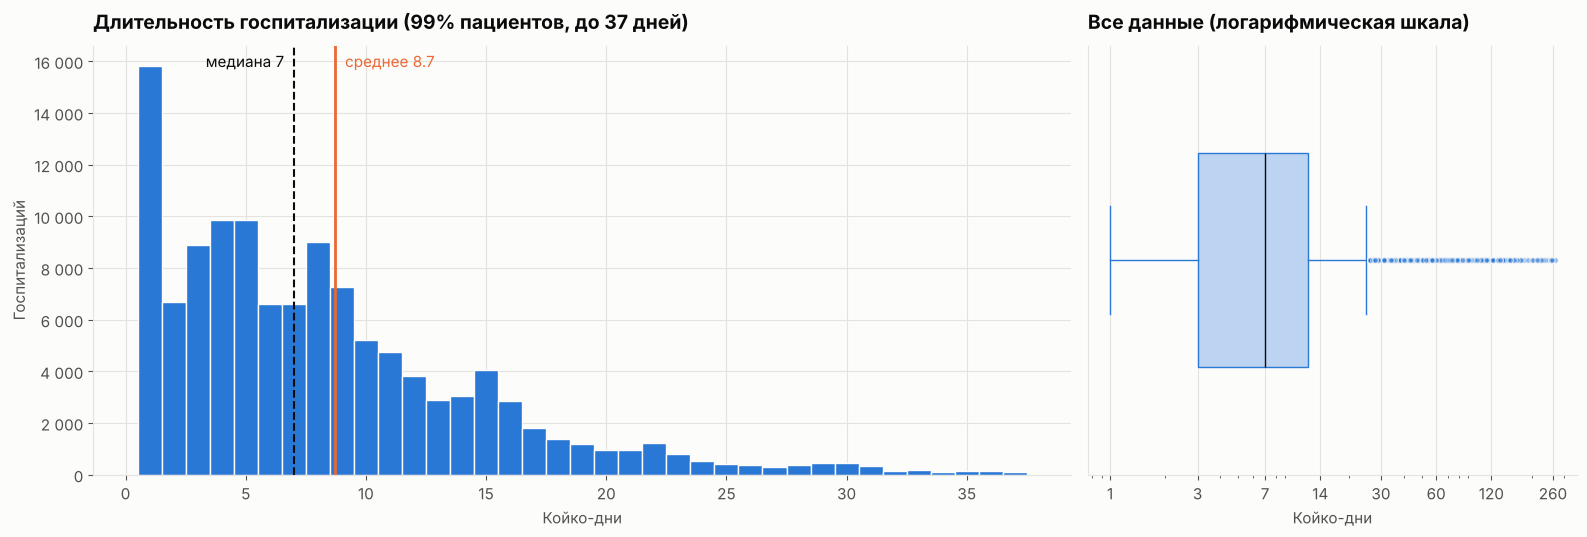

In [12]:
days = df["bed_days"]
print(f"Среднее: {days.mean():.2f}, медиана: {days.median():.0f}, "
      f"75% пациентов — до {days.quantile(.75):.0f} дней, 99% — до {days.quantile(.99):.0f} дней, максимум — {days.max()}")
print(f"Асимметрия: {days.skew():.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [2, 1]})

# Гистограмма до 99-го перцентиля: длинный хвост ниже отдельно в «ящике с усами»
cut = int(days.quantile(.99))
ax1.hist(days[days <= cut], bins=np.arange(0.5, cut + 1.5), color=BLUE, edgecolor=SURFACE, linewidth=1)
ax1.axvline(days.median(), color=INK, linestyle="--", linewidth=1.5)
ax1.axvline(days.mean(), color=ORANGE, linestyle="-", linewidth=2)
ax1.text(days.median() - 0.4, ax1.get_ylim()[1] * 0.95, f"медиана {days.median():.0f}", ha="right", color=INK)
ax1.text(days.mean() + 0.4, ax1.get_ylim()[1] * 0.95, f"среднее {days.mean():.1f}", ha="left", color=ORANGE)
ax1.set_title(f"Длительность госпитализации (99% пациентов, до {cut} дней)")
ax1.set_xlabel("Койко-дни")
ax1.set_ylabel("Госпитализаций")
thousands(ax1)

ax2.boxplot(days, vert=False, widths=0.5, patch_artist=True,
            boxprops={"facecolor": "#bcd4f2", "edgecolor": BLUE}, medianprops={"color": INK},
            whiskerprops={"color": BLUE}, capprops={"color": BLUE},
            flierprops={"marker": "o", "markersize": 4, "markerfacecolor": BLUE, "markeredgecolor": SURFACE, "alpha": .5})
ax2.set_xscale("log")
ax2.set_xticks([1, 3, 7, 14, 30, 60, 120, 260])
ax2.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax2.set_yticks([])
ax2.set_title("Все данные (логарифмическая шкала)")
ax2.set_xlabel("Койко-дни")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_stay_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# Кто даёт пик в 1 день
one_day = df[df["bed_days"] == 1]
print(f"Госпитализаций длительностью 1 день: {len(one_day):,} ({len(one_day) / len(df):.0%})".replace(",", " "))
one_day["department"].value_counts().head(3).to_frame("госпитализаций на 1 день")

Госпитализаций длительностью 1 день: 15 823 (13%)


,госпитализаций на 1 день
department,
ПЭМП ДПО,11988
Офтальмологическое,1039
Инфекционное отделение №1,680


**Наблюдения**

- Типичная госпитализация — **7 дней** (медиана), половина пациентов лежит от 3 до 12 дней.
- Распределение сильно скошено вправо: среднее (8,7) выше медианы за счёт длинного хвоста. Отдельные пациенты
  лежат месяцами, максимум — 266 дней. Это не ошибки, а тяжёлые случаи (реанимация, выхаживание новорождённых).
- Заметный пик в **1 день** почти целиком даёт отделение **ПЭМП ДПО**: там около 12 тыс. госпитализаций,
  и все длятся сутки. По сути это кратковременное наблюдение, а не лечение в стационаре. Оно заметно сдвигает
  статистику вниз, особенно у экстренных пациентов, — учтём это при проверке гипотез.

### 3.2. Отделения с самой долгой госпитализацией

In [14]:
by_dept = (
    df.groupby("department", observed=True)["bed_days"]
    .agg(госпитализаций="count", среднее="mean", медиана="median")
    .sort_values("среднее", ascending=False)
)

# Отделения с малым числом пациентов дают неустойчивое среднее: несколько тяжёлых случаев его сильно сдвигают
MIN_STAYS = 100
top10 = by_dept[by_dept["госпитализаций"] >= MIN_STAYS].head(10)
print(f"Отделений всего: {len(by_dept)}, с числом госпитализаций от {MIN_STAYS}: {(by_dept['госпитализаций'] >= MIN_STAYS).sum()}")
top10

Отделений всего: 35, с числом госпитализаций от 100: 31


,госпитализаций,среднее,медиана
department,,,
ПЦ ОАРИТН №1 (новорожденных),112,28.72,11.00
ПЦ Отделение Анестезиологии-реанимации для детей с кардиохирургической патологией,105,26.44,18.00
ПЦ Отделение патологии новорожденных и детей грудного возраста,2388,22.20,14.00
ПЦ Отделение вспомогательных репродуктивных технологий ДС,910,21.30,20.00
Дневной стационар Кожно-венерологического отделения,183,14.03,15.00
Дневной стационар Гастроэнтерологического отделения,280,13.34,13.00
Микрохирургическое отделение,4662,13.29,10.00
Педиатрическое отделение №1,3490,12.82,12.00
Отделение для детей с новой коронавирусной инфекцией COVID-19 с палатами реанимации и интенсивной терапии,379,12.10,10.00


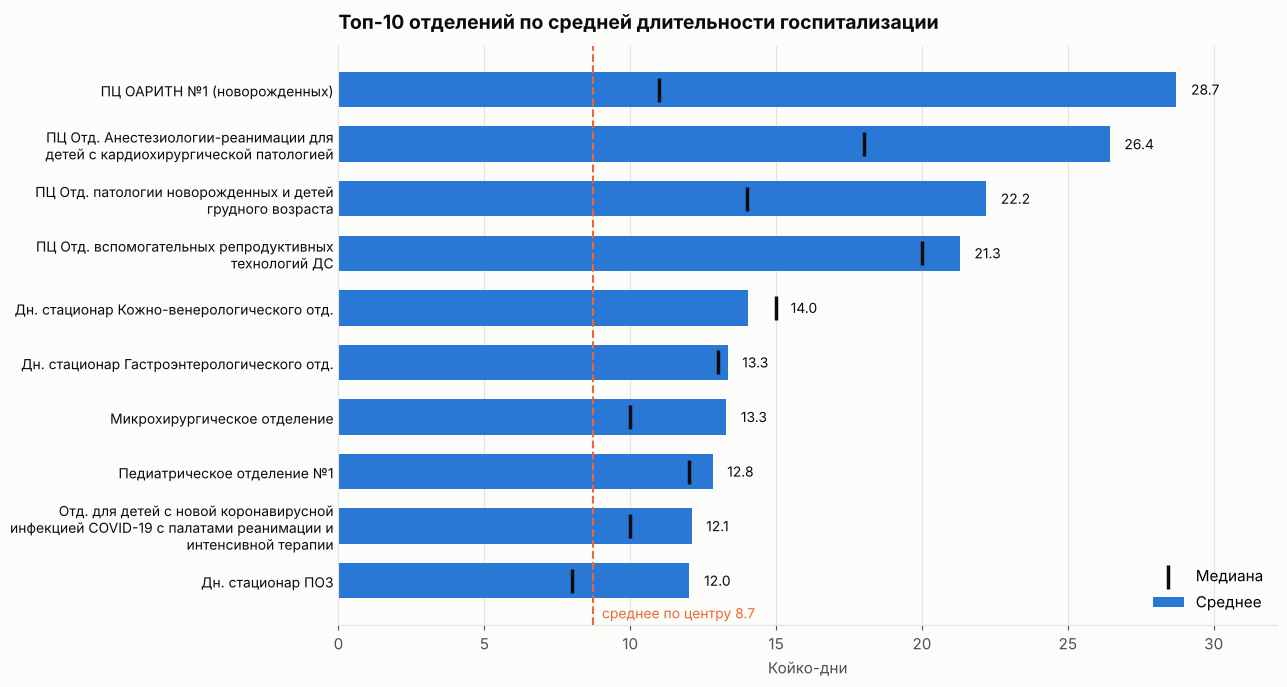

In [15]:
import textwrap

fig, ax = plt.subplots(figsize=(13, 7))
# Длинные названия отделений сокращаем и переносим, чтобы график не растягивался вбок
short = (top10.index.astype(str)
         .str.replace("Отделение", "Отд.", regex=False).str.replace("отделения", "отд.", regex=False)
         .str.replace("Дневной стационар", "Дн. стационар", regex=False))
names = ["\n".join(textwrap.wrap(n, 42)) for n in short]
ax.barh(names, top10["среднее"], color=BLUE, height=0.65, label="Среднее")
ax.scatter(top10["медиана"], names, color=INK, marker="|", s=300, linewidths=2.5, zorder=3, label="Медиана")
for y, (mean, median) in enumerate(zip(top10["среднее"], top10["медиана"])):
    ax.text(max(mean, median) + 0.5, y, f"{mean:.1f}", va="center", color=INK, fontsize=10)
ax.invert_yaxis()
ax.axvline(df["bed_days"].mean(), color=ORANGE, linewidth=1.5, linestyle="--")
ax.text(df["bed_days"].mean() + 0.3, 9.75, f"среднее по центру {df['bed_days'].mean():.1f}",
        color=ORANGE, fontsize=10, va="bottom")
ax.set_title("Топ-10 отделений по средней длительности госпитализации")
ax.set_xlabel("Койко-дни")
ax.set_xlim(0, top10["среднее"].max() * 1.12)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK, labelsize=10)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_top10_departments.png", dpi=150, bbox_inches="tight")
plt.show()

**Наблюдения**

- Дольше всего лежат пациенты **перинатального центра** (ПЦ): отделения реанимации и выхаживания новорождённых,
  вспомогательных репродуктивных технологий. Там госпитализация в 2,5–3 раза длиннее средней по центру.
- В отделениях реанимации среднее заметно выше медианы: большинство пациентов лежит относительно недолго,
  но отдельные тяжёлые случаи длятся месяцами.
- Отделение анестезиологии-реанимации со средним 45 дней в рейтинг не попало: у него всего 78 госпитализаций,
  и среднее держится на нескольких очень долгих случаях.

### 3.3. Динамика поступлений по месяцам

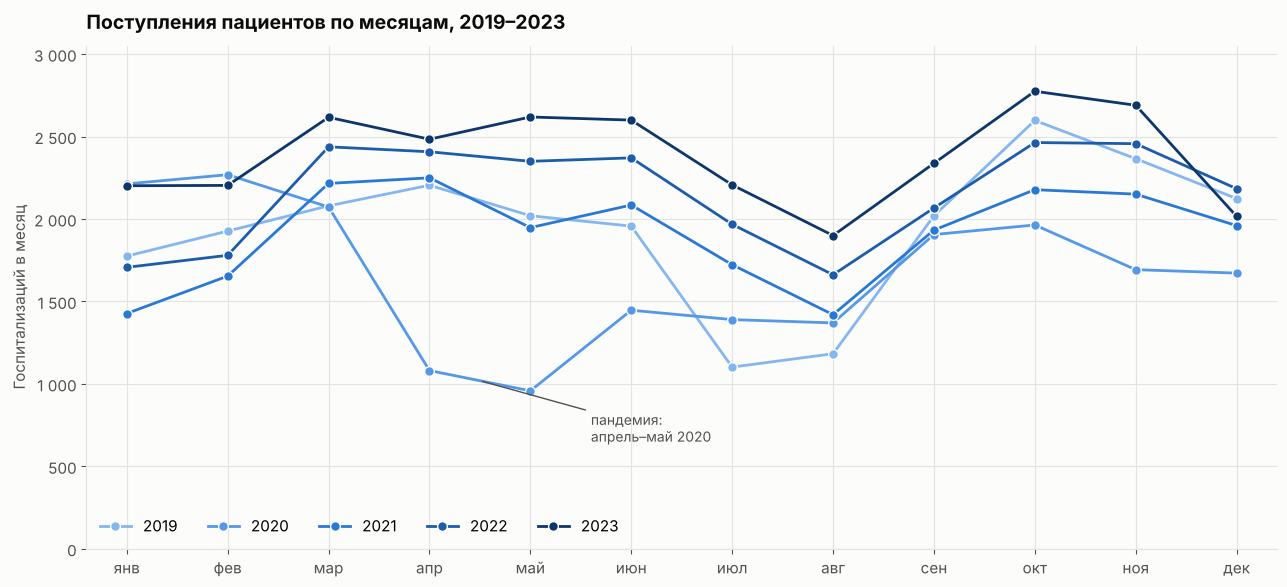

In [16]:
monthly = df.groupby(["year", "month"]).size().unstack("year")
month_names = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]

fig, ax = plt.subplots(figsize=(13, 6))
for color, year in zip(YEAR_RAMP, monthly.columns):
    ax.plot(monthly.index, monthly[year], color=color, marker="o", markersize=7,
            markeredgecolor=SURFACE, linewidth=2, label=str(year))
ax.annotate("пандемия:\nапрель–май 2020", (4.5, monthly.loc[[4, 5], 2020].mean()), xytext=(5.6, 650),
            arrowprops={"arrowstyle": "-", "color": INK_MUTED}, color=INK_MUTED, fontsize=10)
ax.set_xticks(range(1, 13), month_names)
ax.set_xlim(0.6, 12.4)
ax.set_ylim(0, monthly.values.max() * 1.1)
ax.set_title("Поступления пациентов по месяцам, 2019–2023")
ax.set_ylabel("Госпитализаций в месяц")
thousands(ax)
ax.legend(loc="lower left", ncols=5)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_monthly_admissions.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
yearly = df.groupby("year").agg(госпитализаций=("bed_days", "size"), средняя_длительность=("bed_days", "mean"))
yearly["рост_к_прошлому_году"] = yearly["госпитализаций"].pct_change()
yearly.style.format({"госпитализаций": "{:,.0f}", "средняя_длительность": "{:.2f}", "рост_к_прошлому_году": "{:+.1%}"}, na_rep="—")

,госпитализаций,средняя_длительность,рост_к_прошлому_году
year,,,
2019,"23,357",8.77,—
2020,"20,036",8.88,-14.2%
2021,"22,945",9.19,+14.5%
2022,"25,856",8.52,+12.7%
2023,"28,652",8.42,+10.8%


**Наблюдения**

- **Пандемия 2020 года:** в апреле–мае поступлений было вдвое меньше обычного — плановые госпитализации
  переносили. За год поток упал на 14%.
- **После 2020 года поток растёт на 11–15% в год** и в 2023 году достиг максимума — около 28,7 тыс. госпитализаций,
  на 23% больше доковидного 2019-го.
- **Сезонность повторяется каждый год:** провал в июле–августе (летние отпуска, меньше плановых поступлений)
  и пик в октябре–ноябре.
- Средняя длительность по годам почти не меняется (8,5–9,3 дня), то есть рост нагрузки идёт за счёт
  числа пациентов, а не за счёт удлинения лечения.

## Шаг 4. Проверка гипотез

Выборка большая — около 121 тыс. госпитализаций. При таком объёме даже крошечная разница становится
статистически значимой, поэтому для каждой гипотезы кроме p-value смотрим на **размер эффекта**: насколько велика
разница в днях и её 95%-й доверительный интервал. Распределение длительности скошено, но благодаря размеру выборки
распределение выборочного среднего близко к нормальному (ЦПТ), и t-тест применим.

In [18]:
def fmt_p(p):
    # p-value в читаемом виде: очень маленькие значения не округляются до «0.00»
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def mean_ci(x, level=0.95):
    # Доверительный интервал для среднего
    return st.t.interval(level, len(x) - 1, loc=x.mean(), scale=st.sem(x))

days = df["bed_days"]
low, high = mean_ci(days)
print(f"Средняя длительность: {days.mean():.2f} дня, 95% ДИ: [{low:.2f}; {high:.2f}]")

Средняя длительность: 8.73 дня, 95% ДИ: [8.68; 8.78]


### 4.1. Отличается ли средняя длительность от стандартных 7 дней?

- **H₀:** средняя длительность госпитализации = 7 дней.
- **H₁:** средняя длительность ≠ 7 дней (двусторонняя гипотеза).

In [19]:
res_7 = st.ttest_1samp(days, 7)
print(f"t = {res_7.statistic:.1f}, p-value {fmt_p(res_7.pvalue)}")
print("Отвергаем H₀" if res_7.pvalue < ALPHA else "Не удалось отвергнуть H₀")
print(f"Разница со стандартом: {days.mean() - 7:+.2f} дня")

t = 68.6, p-value < 0.001
Отвергаем H₀
Разница со стандартом: +1.73 дня


**Вывод.** H₀ отвергаем: в среднем пациенты лежат **8,7 дня — на 1,7 дня дольше** стандартного срока,
и весь доверительный интервал лежит выше 7. При этом **медиана ровно 7 дней**: типичный пациент укладывается
в стандарт, а среднее завышают длинные госпитализации меньшинства. Для руководства важно, какую метрику
считать целевой: по медиане центр в стандарте, по среднему — нет.

### 4.2. Превышает ли средняя длительность 10 дней?

- **H₀:** средняя длительность = 10 дней.
- **H₁:** средняя длительность > 10 дней (односторонняя гипотеза).

In [20]:
res_10 = st.ttest_1samp(days, 10, alternative="greater")
print(f"t = {res_10.statistic:.1f}, p-value = {fmt_p(res_10.pvalue)}")
print("Отвергаем H₀" if res_10.pvalue < ALPHA else "Не удалось отвергнуть H₀")
print(f"Доля госпитализаций дольше 10 дней: {(days > 10).mean():.0%}")

t = -50.3, p-value = 1.000
Не удалось отвергнуть H₀
Доля госпитализаций дольше 10 дней: 29%


**Вывод.** Нулевую гипотезу отвергнуть не удаётся: среднее (8,7) **ниже** 10 дней, а не выше, и p-value близко к 1.
Предположение медицинского отдела не подтверждается. Дольше 10 дней лежат 29% пациентов,
в основном в перинатальном центре и хирургии.

### 4.3. Различается ли длительность у плановых и экстренных пациентов?

- **H₀:** средняя длительность у плановых и экстренных пациентов одинакова.
- **H₁:** средняя длительность различается (двусторонняя гипотеза).

Группы разного размера и с разным разбросом, поэтому используем **t-тест Уэлча** (`equal_var=False`),
а для устойчивости к выбросам дополнительно — **критерий Манна — Уитни**. Отдельно проверим результат
без отделения кратковременного наблюдения (ПЭМП ДПО), где все пребывания длятся сутки.

In [21]:
def compare(data, label):
    planned = data.loc[data["admission_type"] == "Плановая", "bed_days"]
    urgent = data.loc[data["admission_type"] == "Экстренная", "bed_days"]
    welch = st.ttest_ind(planned, urgent, equal_var=False)
    mwu = st.mannwhitneyu(planned, urgent)
    diff = planned.mean() - urgent.mean()
    se = np.sqrt(planned.var() / len(planned) + urgent.var() / len(urgent))
    return {
        "выборка": label,
        "плановые, среднее": planned.mean(), "экстренные, среднее": urgent.mean(),
        "плановые, медиана": planned.median(), "экстренные, медиана": urgent.median(),
        "разница, дней": diff, "95% ДИ разницы": f"[{diff - 1.96 * se:.2f}; {diff + 1.96 * se:.2f}]",
        "p-value Уэлча": fmt_p(welch.pvalue), "p-value Манна — Уитни": fmt_p(mwu.pvalue),
        "_p": welch.pvalue,
    }

comparison = pd.DataFrame([
    compare(df, "все госпитализации"),
    compare(df[~df["is_observation"]], "без ПЭМП ДПО"),
]).set_index("выборка")
p_planned_vs_urgent = comparison.loc["все госпитализации", "_p"]
comparison = comparison.drop(columns="_p").T
comparison

выборка,все госпитализации,без ПЭМП ДПО
"плановые, среднее",9.72,9.72
"экстренные, среднее",6.25,9.05
"плановые, медиана",8.00,8.00
"экстренные, медиана",3.00,7.00
"разница, дней",3.47,0.68
95% ДИ разницы,[3.35; 3.58],[0.53; 0.82]
p-value Уэлча,< 0.001,< 0.001
p-value Манна — Уитни,< 0.001,< 0.001


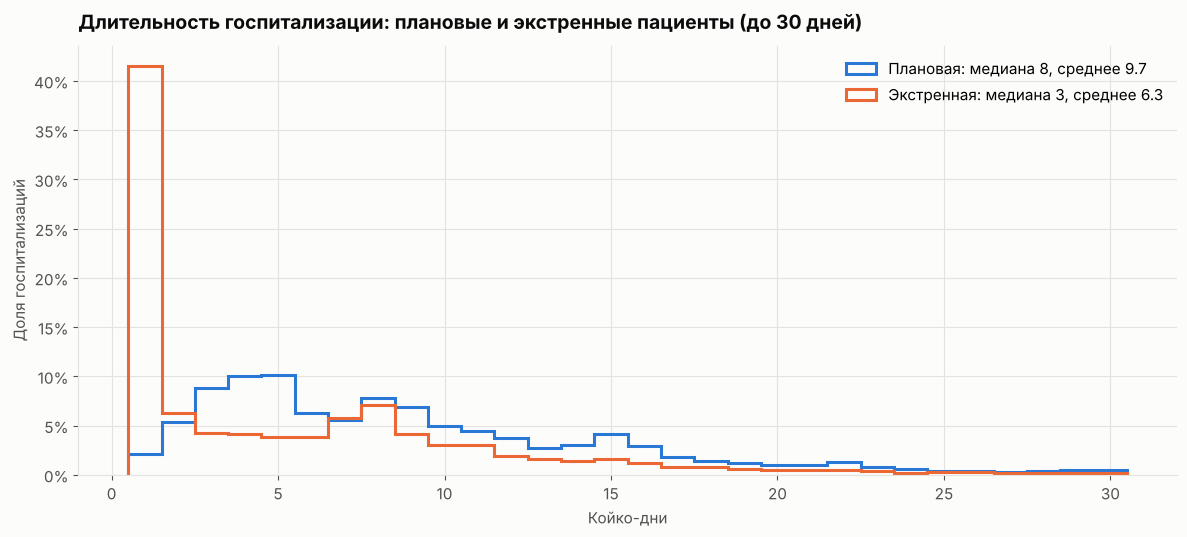

In [22]:
fig, ax = plt.subplots(figsize=(12, 5.5))
bins = np.arange(0.5, 31.5)
for kind, color in [("Плановая", BLUE), ("Экстренная", ORANGE)]:
    part = df.loc[df["admission_type"] == kind, "bed_days"]
    ax.hist(part[part <= 30], bins=bins, density=True, histtype="step", linewidth=2.2, color=color,
            label=f"{kind}: медиана {part.median():.0f}, среднее {part.mean():.1f}")
ax.set_title("Длительность госпитализации: плановые и экстренные пациенты (до 30 дней)")
ax.set_xlabel("Койко-дни")
ax.set_ylabel("Доля госпитализаций")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_planned_vs_urgent.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод.** Формально H₀ отвергаем: плановые пациенты лежат в среднем **9,7 дня**, экстренные — **6,3**
(медианы 8 и 3), оба теста дают p-value < 0.001.

Но почти вся разница — это эффект одного отделения. В ПЭМП ДПО 12 тыс. экстренных пациентов, и все проводят
там сутки. Если его исключить, экстренные пациенты лежат в среднем **9,1 дня** против 9,7 у плановых, а разница
сокращается с 3,5 до **0,7 дня** — примерно в пять раз. Она остаётся статистически значимой из-за огромной выборки,
но практически невелика: меньше суток.

То есть экстренно поступившие и затем госпитализированные пациенты лечатся почти столько же, сколько плановые.
Разрыв в общей статистике создают суточные пребывания в отделении наблюдения.

## Шаг 5. Итоги проверки гипотез

In [23]:
summary = pd.DataFrame({
    "гипотеза": [
        "Средняя длительность ≠ 7 дней",
        "Средняя длительность > 10 дней",
        "Длительность у плановых и экстренных различается",
    ],
    "p-value": [res_7.pvalue, res_10.pvalue, p_planned_vs_urgent],
    "факт": [
        f"среднее {days.mean():.1f} дня (медиана {days.median():.0f})",
        f"среднее {days.mean():.1f} дня",
        f"плановые {comparison.loc['плановые, среднее', 'все госпитализации']:.1f} vs "
        f"экстренные {comparison.loc['экстренные, среднее', 'все госпитализации']:.1f}",
    ],
})
summary["результат"] = np.where(summary["p-value"] < ALPHA, "подтверждается", "не подтверждается")
summary["p-value"] = summary["p-value"].map(fmt_p)
summary.loc[2, "результат"] += " (без ПЭМП ДПО разница всего 0,7 дня)"
summary

,гипотеза,p-value,факт,результат
0,Средняя длительность ≠ 7 дней,< 0.001,среднее 8.7 дня (медиана 7),подтверждается
1,Средняя длительность > 10 дней,1.000,среднее 8.7 дня,не подтверждается
2,Длительность у плановых и экстренных различается,< 0.001,плановые 9.7 vs экстренные 6.3,"подтверждается (без ПЭМП ДПО разница всего 0,7 дня)"


## Общие выводы и рекомендации

**Качество данных**
- Около 3,5% записей — полные дубликаты, они массово появились в выгрузке с 2021 года.
  Нужно проверить процесс выгрузки, иначе поток пациентов будет завышаться.
- У половины госпитализаций не указан регион, а Санкт-Петербург в данных практически отсутствует.
  Вероятно, у местных пациентов поле не заполняют. Регион стоит сделать обязательным полем.
- В данных нет даты выдачи направления. Поэтому исходный вопрос — сколько времени проходит от направления
  до поступления — по этой таблице ответить нельзя. Для этого нужно добавить в выгрузку дату направления.

**Длительность госпитализации**
- Типичный пациент лежит 7 дней, и по медиане центр укладывается в стандарт. Среднее выше (8,7 дня)
  из-за небольшой доли очень долгих госпитализаций. Для отчётности руководству лучше использовать
  медиану и долю пациентов дольше нормы, а не среднее.
- Гипотеза о средней длительности больше 10 дней не подтвердилась.
- Главный фактор длительности — **тип отделения**: перинатальный центр и реанимация дают госпитализации
  в 2–3 раза длиннее средней.
- **Тип поступления** влияет слабее, чем кажется: разница между плановыми и экстренными пациентами (3,5 дня)
  почти целиком объясняется суточными пребываниями в отделении наблюдения. Без них она меньше суток.

**Поток пациентов**
- Поступления растут с 2021 года и в 2023-м на 23% выше доковидного уровня, при этом длительность
  лечения не меняется. Нагрузка на центр растёт за счёт числа пациентов.
- Сезонность устойчива: провал летом и пик осенью. Плановые госпитализации можно частично переносить
  на летние месяцы, чтобы сгладить осеннюю нагрузку на койки и персонал.

**Что ещё стоит изучить**
- Отделить кратковременное наблюдение (ПЭМП ДПО) от полноценных госпитализаций в отчётности:
  12 тыс. суточных пребываний заметно занижают среднюю длительность у экстренных пациентов.
- Посмотреть на длинные госпитализации (дольше 30 дней) отдельно по диагнозам — это небольшая доля пациентов,
  но она занимает непропорционально много койко-дней.